In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [25]:
img = cv2.imread('flowers.jpg')
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

h, w = img_gray.shape[:2]  
target_size = 512

left = max(0, (w - target_size) // 2)
top = max(0, (h - target_size) // 2)
right = min(w, left + target_size)
bottom = min(h, top + target_size)

img_512 = img_gray[top:bottom, left:right]  

In [32]:
def haar_1d_fwd(x: np.ndarray) -> np.ndarray:
    even, odd = x[..., 0::2], x[..., 1::2]
    return np.concatenate([(even + odd) / np.sqrt(2), (even - odd) / np.sqrt(2)], axis=-1)


def haar_1d_inv(c: np.ndarray) -> np.ndarray:
    half = c.shape[-1] // 2
    low, high = c[..., :half], c[..., half:]
    out = np.empty_like(c)
    out[..., 0::2] = (low + high) / np.sqrt(2)
    out[..., 1::2] = (low - high) / np.sqrt(2)
    return out

def haar_2d_fwd(img_gray: np.ndarray, levels: int = 3, save_steps: bool = False):
    coeffs = img_gray.astype(np.float32).copy()
    h, w = coeffs.shape
    steps = []
    for lvl in range(levels):
        sh, sw = h // (2 ** lvl), w // (2 ** lvl)
        hh, hw = sh // 2, sw // 2
        t = haar_1d_fwd(haar_1d_fwd(coeffs[:sh, :sw]).T).T
        ll, hl, lh, hh_band = t[:hh, :hw], t[hh:, :hw], t[:hh, hw:], t[hh:, hw:]
        coeffs[:sh, :sw] = np.block([[ll, lh], [hl, hh_band]])
        if save_steps:
            steps.append(coeffs.copy())
    return (coeffs, steps) if save_steps else coeffs

def haar_2d_inv(coeffs: np.ndarray, levels: int = 3) -> np.ndarray:
    rec = coeffs.copy()
    h, w = rec.shape
    for lvl in reversed(range(levels)):
        sh, sw = h // (2 ** lvl), w // (2 ** lvl)
        hh, hw = sh // 2, sw // 2
        b = rec[:sh, :sw]
        ll, lh, hl, hh_band = b[:hh, :hw], b[:hh, hw:], b[hh:, :hw], b[hh:, hw:]
        t = np.block([[ll, lh], [hl, hh_band]])
        rec[:sh, :sw] = haar_1d_inv(haar_1d_inv(t.T).T)
    return rec

In [33]:
img_512_float = img_512.astype(np.float32)
coeffs, steps = haar_2d_fwd(img_512_float, levels=3, save_steps=True)

compressed = coeffs.copy()
thresholds = {1: 10.0, 2: 5.0, 3: 2.0}
h, w = compressed.shape
for lvl in (1, 2, 3):
    sh, sw = h // (2 ** (lvl - 1)), w // (2 ** (lvl - 1))
    hh, hw = sh // 2, sw // 2
    thr = thresholds[lvl]
    for r_sl, c_sl in [(slice(0, hh), slice(hw, sw)), (slice(hh, sh), slice(0, hw)), (slice(hh, sh), slice(hw, sw))]:
        sub = compressed[r_sl, c_sl]
        sub[np.abs(sub) < thr] = 0.0

rec = np.clip(haar_2d_inv(compressed, levels=3), 0, 255)
rmse = np.sqrt(np.mean((img_512 - rec) ** 2))
psnr = 20 * np.log10(255.0 / rmse) if rmse > 0 else float("inf")
print(f"Ненулевых коэффициентов: {np.count_nonzero(compressed)} / {compressed.size} | RMSE={rmse:.2f} | PSNR={psnr:.2f} дБ")

Ненулевых коэффициентов: 54199 / 262144 | RMSE=2.53 | PSNR=40.05 дБ


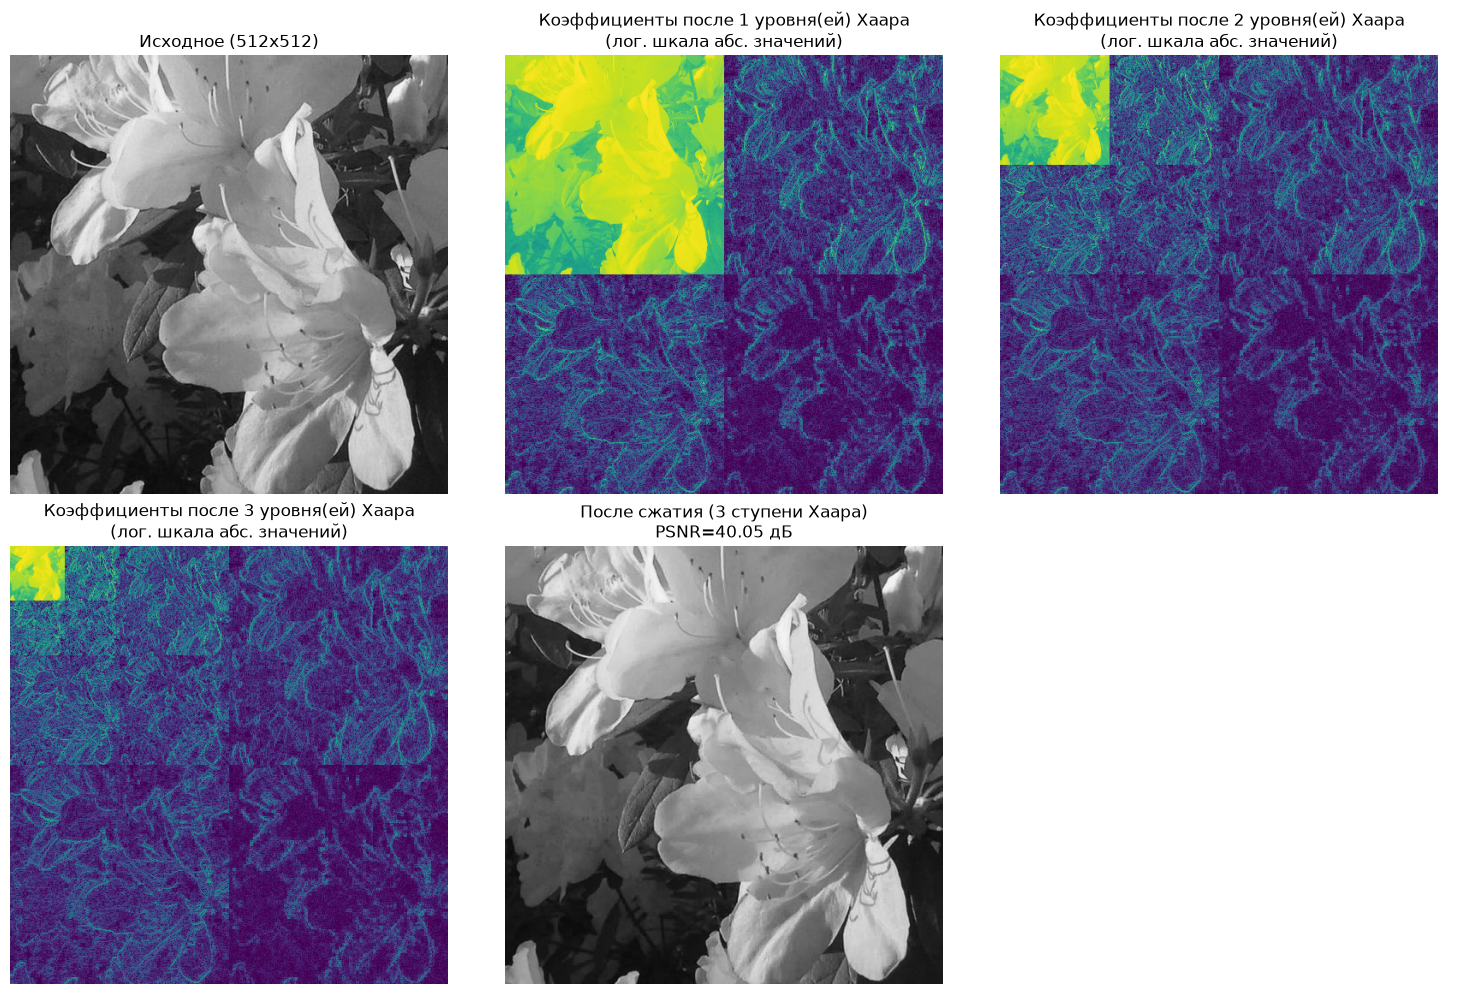

In [34]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()

axes[0].imshow(img_512, cmap='gray', vmin=0, vmax=255)
axes[0].set_title("Исходное (512x512)")
axes[0].axis('off')

for i, step in enumerate(steps):
    vis = np.log1p(np.abs(step))
    axes[i + 1].imshow(vis, cmap='viridis')
    axes[i + 1].set_title(f"Коэффициенты после {i + 1} уровня(ей) Хаара\n(лог. шкала абс. значений)")
    axes[i + 1].axis('off')

axes[4].imshow(rec, cmap='gray', vmin=0, vmax=255)
axes[4].set_title(f"После сжатия (3 ступени Хаара)\nPSNR={psnr:.2f} дБ")
axes[4].axis('off')

axes[5].axis('off')

plt.tight_layout()
plt.show()